In [2]:
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
from PIL import Image, ImageDraw, ImageFont
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [14]:
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

def crop_face(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5
    )

    if len(faces) > 0:
        x, y, w, h = faces[0]
        return img[y:y+h, x:x+w] 

    return img

In [10]:
def add_grid_title_same_size(img, title):
    if len(img.shape) == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    _, w = img.shape[:2]

    title_space = np.ones((60, w, 3), dtype=np.uint8) * 255

    pil_img = Image.fromarray(title_space)
    draw = ImageDraw.Draw(pil_img)
    font = ImageFont.truetype("arial.ttf", 28)

    bbox = draw.textbbox((0, 0), title, font=font)

    text_width = bbox[2] - bbox[0]
    text_height = bbox[3] - bbox[1]

    x = (w - text_width) // 2
    y = (60 - text_height) // 2

    draw.text((x, y), title, font=font, fill=(0, 0, 0))
    title_space = np.array(pil_img)
    result = np.vstack((title_space, img))

    return result

In [8]:
def Save_Display_Enhancement_Comparisons(images, titles, file_name, final_display_size, output_folder):
    target_size = (300, 300)

    images_title = []

    for img, title in zip(images, titles):
        img = cv2.resize(img, target_size)
        img_title = add_grid_title_same_size(img, title)
        images_title.append(img_title)

    reference = images_title[0]

    rows = []

    for img in images_title[1:]:
        rows.append(
            np.hstack((reference, img))
        )

    final_display = np.vstack(rows)

    final_display = cv2.resize(
        final_display,
        final_display_size
    )

    os.makedirs(output_folder, exist_ok=True)

    cv2.imwrite(
        os.path.join(output_folder, file_name),
        final_display
    )

    cv2.imshow(file_name, final_display)

    cv2.waitKey(5000)
    cv2.destroyAllWindows()

In [16]:
img_FER = cv2.imread(r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Used Dataset\FER2013\train\fear\Training_358270.jpg")
img_KDEF = cv2.imread(r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Used Dataset\KDEF_and_AKDEF\KDEF\AF01\AF01AFS.JPG")
img_CK = cv2.imread(r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Used Dataset\CK+\fear\S011_003_00000012.png")

In [7]:
print(img_FER.shape)
print(img_KDEF.shape)
print(img_CK.shape)

(48, 48, 3)
(762, 562, 3)
(48, 48, 3)


# Face Cropping KDEF

In [17]:
cropped_face_kdef = crop_face(img_KDEF)

output_folder = r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Prepocessing Output Sample\Face Cropping KDEF"
Save_Display_Enhancement_Comparisons(images=[img_KDEF, cropped_face_kdef], titles=["Original KDEF","Cropped Face KDEF"], file_name="Before & After Cropping.jpg", final_display_size = (700,800), output_folder=output_folder)

# Grayscale

In [22]:
gray_FER = cv2.cvtColor(img_FER, cv2.COLOR_RGB2GRAY)

output_folder = r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Prepocessing Output Sample\Grayscale\FER2013"
Save_Display_Enhancement_Comparisons(images=[img_FER , gray_FER], titles=["Original FER2013", "Grayscale FER2013"], file_name="Before After Grayscale FER.jpg",final_display_size = (700,800), output_folder=output_folder)

cropped_gray_KDEF = cv2.cvtColor(cropped_face_kdef, cv2.COLOR_RGB2GRAY)
output_folder = r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Prepocessing Output Sample\Grayscale\KDEF"
Save_Display_Enhancement_Comparisons(images=[cropped_face_kdef , cropped_gray_KDEF], titles=["Cropped KDEF", "Cropped Grayscale KDEF"], file_name="Before After Grayscale KDEF.jpg",final_display_size = (700,800), output_folder=output_folder)

gray_CK = cv2.cvtColor(img_CK, cv2.COLOR_RGB2GRAY)

output_folder = r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Prepocessing Output Sample\Grayscale\CK+"
Save_Display_Enhancement_Comparisons(images=[img_CK , gray_CK], titles=["Original CK+", "Grayscale CK+"], file_name="Before After Grayscale CK+.jpg",final_display_size = (700,800), output_folder=output_folder)

Shape atau Dimensi Before & After Grayscale 

In [10]:
print(f"Dimensi atau Shape dari Sampel Dataset FER Sebelum Grayscale : {img_FER.shape}")
print(f"Dimensi atau Shape dari Sampel Dataset FER Sesudah Grayscale : {gray_FER.shape}")

Dimensi atau Shape dari Sampel Dataset FER Sebelum Grayscale : (48, 48, 3)
Dimensi atau Shape dari Sampel Dataset FER Sesudah Grayscale : (48, 48)


In [11]:
print(f"Dimensi atau Shape dari Sampel Dataset KDEF Sebelum Grayscale : {cropped_face_kdef.shape}")
print(f"Dimensi atau Shape dari Sampel Dataset KDEF Sesudah Grayscale : {cropped_gray_KDEF.shape}")

Dimensi atau Shape dari Sampel Dataset KDEF Sebelum Grayscale : (392, 392, 3)
Dimensi atau Shape dari Sampel Dataset KDEF Sesudah Grayscale : (392, 392)


In [12]:
print(f"Dimensi atau Shape dari Sampel Dataset CK+ Sebelum Grayscale : {img_CK.shape}")
print(f"Dimensi atau Shape dari Sampel Dataset CK+ Sesudah Grayscale : {gray_CK.shape}")

Dimensi atau Shape dari Sampel Dataset CK+ Sebelum Grayscale : (48, 48, 3)
Dimensi atau Shape dari Sampel Dataset CK+ Sesudah Grayscale : (48, 48)


Pixel Intensity Value Before & After Grayscale 

In [13]:
print(f"Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset FER Sebelum Grayscale : {img_FER[0,0]}")
print(f"Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset FER Sesudah Grayscale : {gray_FER[0,0]}")

Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset FER Sebelum Grayscale : [129 129 129]
Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset FER Sesudah Grayscale : 129


In [14]:
print(f"Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset KDEF Sebelum Grayscale : {cropped_face_kdef[0,0]}")
print(f"Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset KDEF Sesudah Grayscale : {cropped_gray_KDEF[0,0]}")

Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset KDEF Sebelum Grayscale : [102 129 149]
Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset KDEF Sesudah Grayscale : 123


In [15]:
print(f"Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset CK+ Sebelum Grayscale : {img_CK[0,0]}")
print(f"Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset CK+ Sesudah Grayscale : {gray_CK[0,0]}")

Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset CK+ Sebelum Grayscale : [255 255 255]
Nilai Intensitas Piksel pada koordinat [0,0] dari Sampel Dataset CK+ Sesudah Grayscale : 255


# HE, CS, CS-HE

In [4]:
def apply_histogram_equalization(gray):
    return cv2.equalizeHist(gray)

In [5]:
def apply_contrast_stretching(gray):
  
    min_val = gray.min()
    max_val = gray.max()

    if max_val - min_val == 0:
        stretched = gray
    else:
        stretched = ((gray - min_val) / (max_val - min_val) * 255).astype(np.uint8)

    return stretched

In [6]:
def apply_cs_he(gray):
    cs = apply_contrast_stretching(gray)
    return apply_histogram_equalization(cs)

In [28]:
gray_FER = cv2.cvtColor(img_FER, cv2.COLOR_RGB2GRAY)
he_FER = apply_histogram_equalization(gray_FER)
cs_FER = apply_contrast_stretching(gray_FER)
cs_he_FER =  apply_cs_he(gray_FER)

output_folder = r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Prepocessing Output Sample\Enhancement Comparison\FER2013"
Save_Display_Enhancement_Comparisons(images=[img_FER, gray_FER, he_FER, cs_FER, cs_he_FER], titles=["Original FER","Grayscale FER", "HE FER", "CS FER", "CS_HE FER"], file_name="FER2013 All Methods Enhancement Sample.jpg",final_display_size = (700,800), output_folder=output_folder)

In [23]:
he_KDEF = apply_histogram_equalization(cropped_gray_KDEF)
cs_KDEF = apply_contrast_stretching (cropped_gray_KDEF) 
cs_he_KDEF =  apply_cs_he(cropped_gray_KDEF)

output_folder = r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Prepocessing Output Sample\Enhancement Comparison\KDEF"
Save_Display_Enhancement_Comparisons(images=[cropped_gray_KDEF , he_KDEF, cs_KDEF, cs_he_KDEF], titles=["Grayscale Cropped KDEF", "HE KDEF", "CS KDEF", "CS_HE KDEF"], file_name="KDEF All Methods Enhancement Sample.jpg",final_display_size = (700,800), output_folder=output_folder)

In [24]:
img_CK = cv2.imread(r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Used Dataset\CK+\fear\S011_003_00000012.png")

gray_CK = cv2.cvtColor(img_CK, cv2.COLOR_RGB2GRAY)
he_CK = apply_histogram_equalization(gray_CK)
cs_CK = apply_contrast_stretching (gray_CK)
cs_he_CK =  apply_cs_he(gray_CK)

output_folder = r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Prepocessing Output Sample\Enhancement Comparison\CK+"
Save_Display_Enhancement_Comparisons(images=[img_CK, he_CK, cs_CK, cs_he_CK], titles=["Original CK", "HE CK", "CS CK", "CS_HE CK"], file_name="CK+ Enhancement Sample.jpg",final_display_size = (700,800), output_folder=output_folder)

##### Displaying Original Image Shape

In [22]:
print(img_FER.shape)
print(img_KDEF.shape)
print(img_CK.shape)

(48, 48, 3)
(762, 562, 3)
(48, 48, 3)


##### Displaying Grayscale and Enhancement Image Shape

In [23]:
print(gray_CK.shape)
print(he_CK.shape)
print(cs_CK.shape)
print(cs_he_CK.shape)

(48, 48)
(48, 48)
(48, 48)
(48, 48)


In [24]:
print(cropped_gray_KDEF.shape)
print(he_KDEF.shape)
print(cs_KDEF.shape)
print(cs_he_KDEF.shape)

(392, 392)
(392, 392)
(392, 392)
(392, 392)


In [25]:
print(gray_CK.shape)
print(he_CK.shape)
print(cs_CK.shape)
print(cs_he_CK.shape)

(48, 48)
(48, 48)
(48, 48)
(48, 48)


In [26]:
def image_stats(img):
    return {
        'Min': np.min(img),
        'Max': np.max(img),
        'Mean': np.mean(img),
        'Std Dev': np.std(img)
    }

In [27]:
print("FER Original :", image_stats(img_FER))
print("KDEF Original:", image_stats(cropped_gray_KDEF))
print("CK Original :", image_stats(img_CK))

FER Original : {'Min': 6, 'Max': 255, 'Mean': 196.09678819444446, 'Std Dev': 35.01315115172004}
KDEF Original: {'Min': 2, 'Max': 175, 'Mean': 41.637891763848394, 'Std Dev': 28.59946740666269}
CK Original : {'Min': 0, 'Max': 255, 'Mean': 96.46267361111111, 'Std Dev': 57.65781780437857}


In [28]:
print("FER Grayscale :", image_stats(gray_FER))
print("FER HE:", image_stats(he_FER))
print("FER CS :", image_stats(cs_FER))
print("FER CS HE :", image_stats(cs_he_FER))

FER Grayscale : {'Min': 6, 'Max': 255, 'Mean': 196.09678819444446, 'Std Dev': 35.01315115172003}
FER HE: {'Min': 0, 'Max': 255, 'Mean': 129.19270833333334, 'Std Dev': 73.86055284301656}
FER CS : {'Min': 0, 'Max': 255, 'Mean': 194.16710069444446, 'Std Dev': 35.845520373264755}
FER CS HE : {'Min': 0, 'Max': 255, 'Mean': 129.19270833333334, 'Std Dev': 73.86055284301656}


In [29]:
print("KDEF Grayscale :", image_stats(cropped_gray_KDEF))
print("KDEF HE:", image_stats(he_KDEF))
print("KDEF CS :", image_stats(cs_KDEF))
print("KDEF CS HE :", image_stats(cs_he_KDEF))

KDEF Grayscale : {'Min': 2, 'Max': 175, 'Mean': 41.637891763848394, 'Std Dev': 28.59946740666269}
KDEF HE: {'Min': 0, 'Max': 255, 'Mean': 130.19075385256144, 'Std Dev': 71.80211385201318}
KDEF CS : {'Min': 0, 'Max': 255, 'Mean': 57.91079888588088, 'Std Dev': 42.18565443772917}
KDEF CS HE : {'Min': 0, 'Max': 255, 'Mean': 130.19075385256144, 'Std Dev': 71.80211385201318}


In [30]:
print("CK Grayscale :", image_stats(gray_CK))
print("CK HE:", image_stats(he_CK))
print("CK CS :", image_stats(cs_CK))
print("CK CS HE :", image_stats(cs_he_CK))

CK Grayscale : {'Min': 0, 'Max': 255, 'Mean': 96.46267361111111, 'Std Dev': 57.657817804378574}
CK HE: {'Min': 0, 'Max': 255, 'Mean': 127.49088541666667, 'Std Dev': 73.94866077768589}
CK CS : {'Min': 0, 'Max': 255, 'Mean': 96.46267361111111, 'Std Dev': 57.657817804378574}
CK CS HE : {'Min': 0, 'Max': 255, 'Mean': 127.49088541666667, 'Std Dev': 73.94866077768589}


CS-HE HE Pixel Comparison

In [31]:
print("HE FER :", image_stats(he_FER))
print("CS HE FER:", image_stats(cs_he_FER))
print("HE KDEF :", image_stats(he_KDEF))
print("CS HE KDEF :", image_stats(cs_he_KDEF))
print("HE CK :", image_stats(he_CK))
print("CS HE CK:", image_stats(cs_he_CK))

HE FER : {'Min': 0, 'Max': 255, 'Mean': 129.19270833333334, 'Std Dev': 73.86055284301656}
CS HE FER: {'Min': 0, 'Max': 255, 'Mean': 129.19270833333334, 'Std Dev': 73.86055284301656}
HE KDEF : {'Min': 0, 'Max': 255, 'Mean': 130.19075385256144, 'Std Dev': 71.80211385201318}
CS HE KDEF : {'Min': 0, 'Max': 255, 'Mean': 130.19075385256144, 'Std Dev': 71.80211385201318}
HE CK : {'Min': 0, 'Max': 255, 'Mean': 127.49088541666667, 'Std Dev': 73.94866077768589}
CS HE CK: {'Min': 0, 'Max': 255, 'Mean': 127.49088541666667, 'Std Dev': 73.94866077768589}


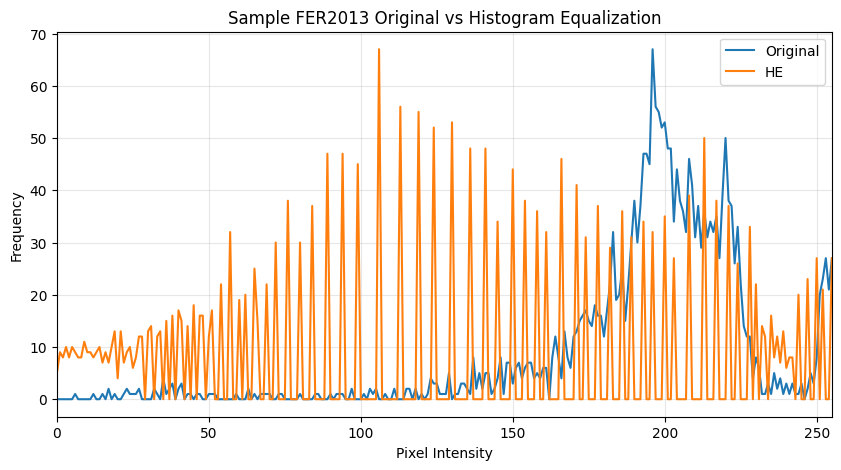

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Histogram Original
hist_ori = cv2.calcHist([img_FER], [0], None, [256], [0,256])

# Histogram HE
hist_he = cv2.calcHist([he_FER], [0], None, [256], [0,256])

plt.figure(figsize=(10,5))

plt.plot(hist_ori, label='Original')
plt.plot(hist_he, label='HE')

plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.title('Sample FER2013 Original vs Histogram Equalization')
plt.xlim([0,255])

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

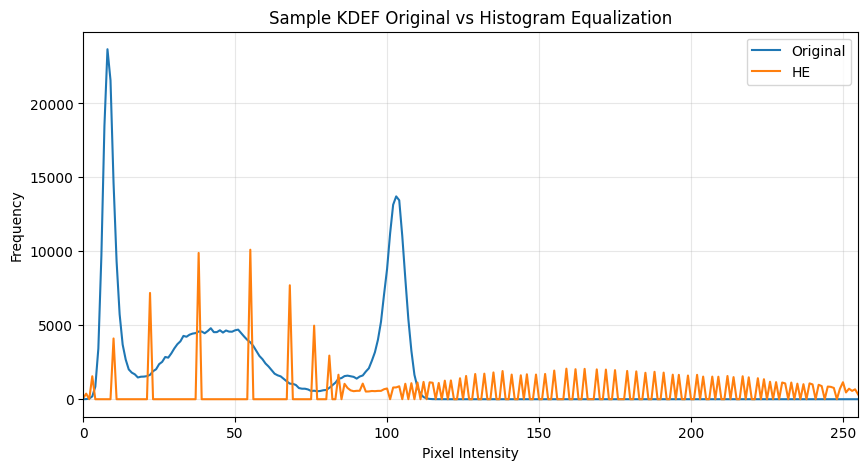

In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Histogram Original
hist_ori = cv2.calcHist([img_KDEF], [0], None, [256], [0,256])

# Histogram HE
hist_he = cv2.calcHist([he_KDEF], [0], None, [256], [0,256])

plt.figure(figsize=(10,5))

plt.plot(hist_ori, label='Original')
plt.plot(hist_he, label='HE')

plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.title('Sample KDEF Original vs Histogram Equalization')
plt.xlim([0,255])

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

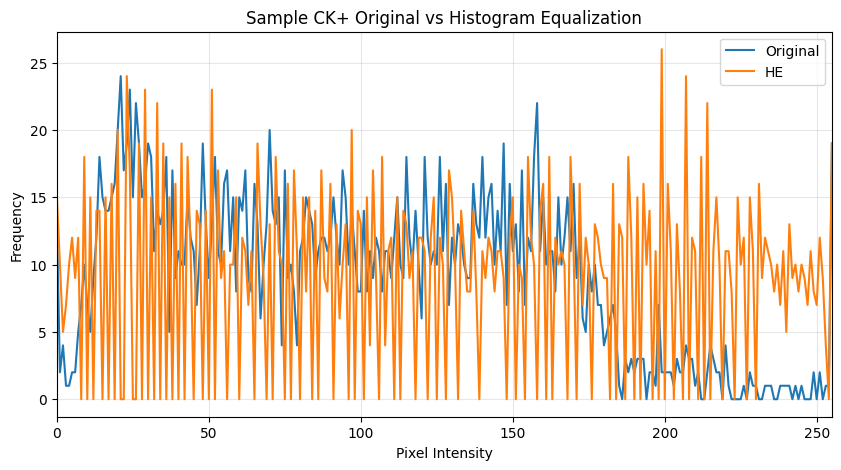

In [34]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Histogram Original
hist_ori = cv2.calcHist([img_CK], [0], None, [256], [0,256])

# Histogram HE
hist_he = cv2.calcHist([he_CK], [0], None, [256], [0,256])

plt.figure(figsize=(10,5))

plt.plot(hist_ori, label='Original')
plt.plot(hist_he, label='HE')

plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.title('Sample CK+ Original vs Histogram Equalization')
plt.xlim([0,255])

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

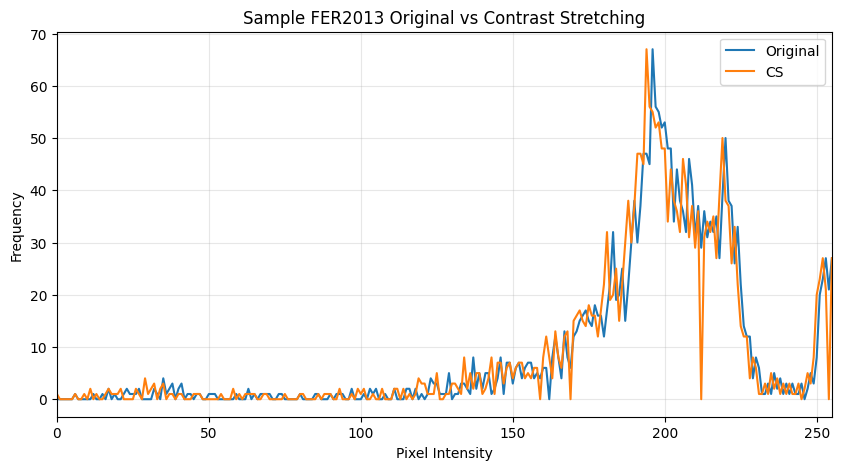

In [29]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Histogram Original
hist_ori = cv2.calcHist([img_FER], [0], None, [256], [0,256])

# Histogram CS
hist_cs = cv2.calcHist([cs_FER], [0], None, [256], [0,256])

plt.figure(figsize=(10,5))

plt.plot(hist_ori, label='Original')
plt.plot(hist_cs, label='CS')

plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.title('Sample FER2013 Original vs Contrast Stretching')
plt.xlim([0,255])

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

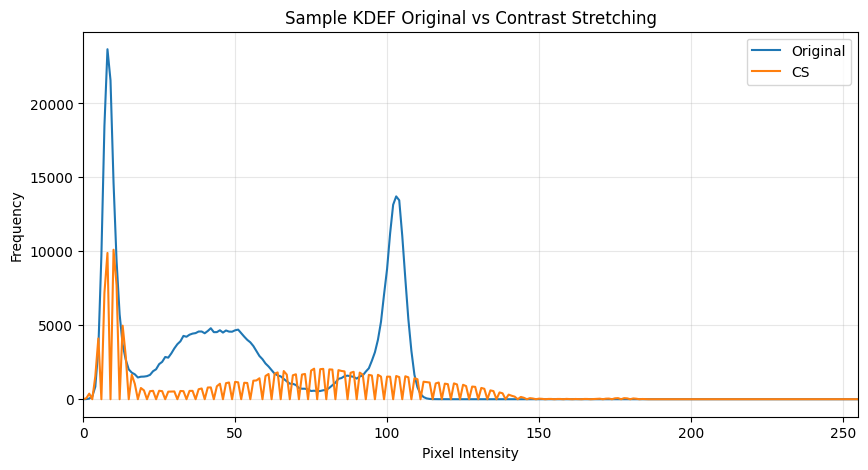

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Histogram Original
hist_ori = cv2.calcHist([img_KDEF], [0], None, [256], [0,256])

# Histogram CS
hist_cs = cv2.calcHist([cs_KDEF], [0], None, [256], [0,256])

plt.figure(figsize=(10,5))

plt.plot(hist_ori, label='Original')
plt.plot(hist_cs, label='CS')

plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.title('Sample KDEF Original vs Contrast Stretching')
plt.xlim([0,255])

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

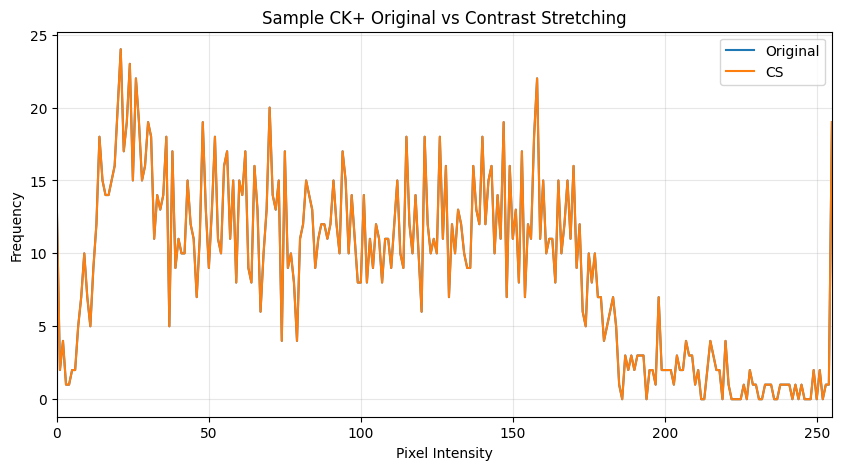

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Histogram Original 
hist_ori = cv2.calcHist([img_CK], [0], None, [256], [0,256])

# Histogram CS
hist_cs = cv2.calcHist([cs_CK], [0], None, [256], [0,256])

plt.figure(figsize=(10,5))

plt.plot(hist_ori, label='Original')
plt.plot(hist_cs, label='CS')

plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.title('Sample CK+ Original vs Contrast Stretching')
plt.xlim([0,255])

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

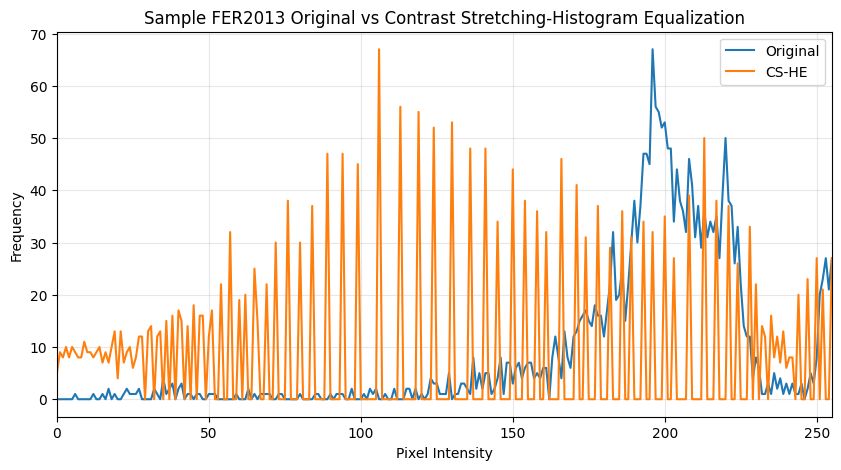

In [30]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Histogram Original
hist_ori = cv2.calcHist([img_FER], [0], None, [256], [0,256])

# Histogram HE
hist_he = cv2.calcHist([cs_he_FER], [0], None, [256], [0,256])

plt.figure(figsize=(10,5))

plt.plot(hist_ori, label='Original')
plt.plot(hist_he, label='CS-HE')

plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.title('Sample FER2013 Original vs Contrast Stretching-Histogram Equalization')
plt.xlim([0,255])

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

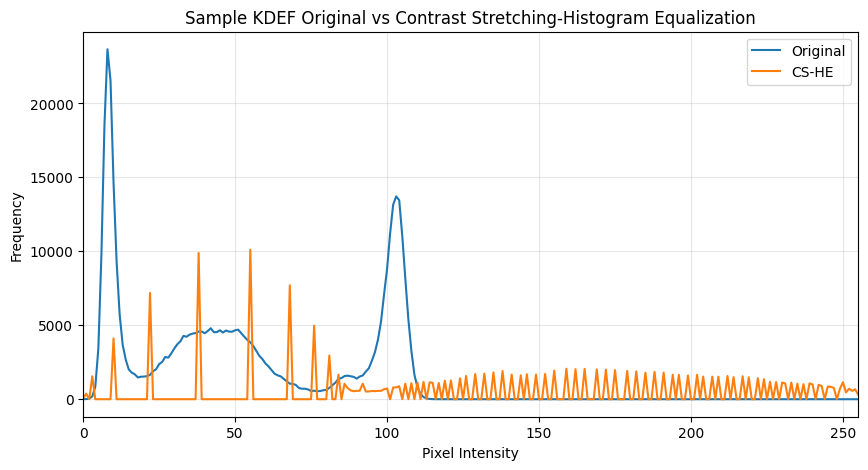

In [39]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Histogram Original
hist_ori = cv2.calcHist([img_KDEF], [0], None, [256], [0,256])

# Histogram HE
hist_he = cv2.calcHist([cs_he_KDEF], [0], None, [256], [0,256])

plt.figure(figsize=(10,5))

plt.plot(hist_ori, label='Original')
plt.plot(hist_he, label='CS-HE')

plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.title('Sample KDEF Original vs Contrast Stretching-Histogram Equalization')
plt.xlim([0,255])

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

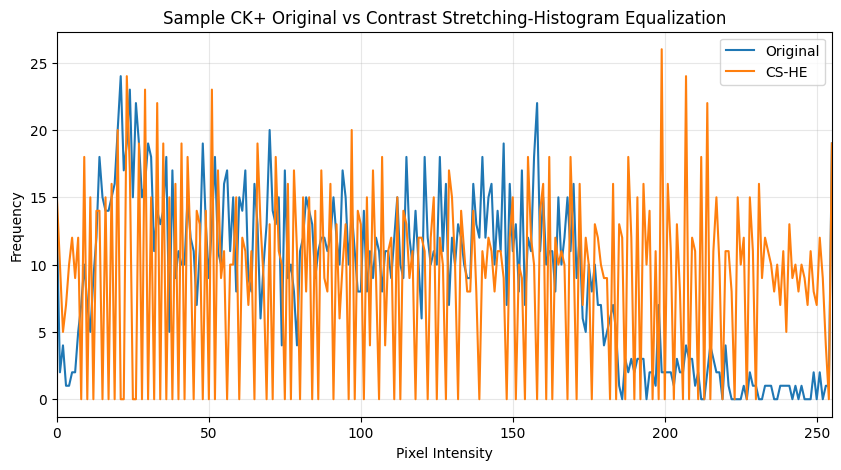

In [40]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Histogram Original
hist_ori = cv2.calcHist([img_CK], [0], None, [256], [0,256])

# Histogram HE
hist_he = cv2.calcHist([cs_he_CK], [0], None, [256], [0,256])

plt.figure(figsize=(10,5))

plt.plot(hist_ori, label='Original')
plt.plot(hist_he, label='CS-HE')

plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.title('Sample CK+ Original vs Contrast Stretching-Histogram Equalization')
plt.xlim([0,255])

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# Resize & Convert RGB Format

In [41]:
img_FER_Resized = cv2.resize(gray_FER, (224, 224))
img_FER_Resized_RGB = cv2.cvtColor(img_FER_Resized, cv2.COLOR_GRAY2RGB)

output_folder = r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Prepocessing Output Sample\Resized & RGB\FER"
Save_Display_Enhancement_Comparisons(images=[img_FER, img_FER_Resized_RGB], titles=["Resized FER", "Resized to RGB FER"], file_name="FER Resized RGB.jpg",final_display_size = (700,800), output_folder=output_folder)

print("Shape FER grayscale :", img_FER_Resized.shape)
print("Shape FER RGB       :", img_FER_Resized_RGB.shape)

print("\nPixel grayscale (0,0):")
print(img_FER_Resized[0, 0])

print("\nPixel RGB (0,0):")
print(img_FER_Resized_RGB[0, 0])

Shape FER grayscale : (224, 224)
Shape FER RGB       : (224, 224, 3)

Pixel grayscale (0,0):
129

Pixel RGB (0,0):
[129 129 129]


In [42]:
img_KDEF_Resized = cv2.resize(cropped_gray_KDEF, (224, 224))
img_KDEF_Resized_RGB = cv2.cvtColor(img_KDEF_Resized, cv2.COLOR_GRAY2RGB)

output_folder = r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Prepocessing Output Sample\Resized & RGB\KDEF"
Save_Display_Enhancement_Comparisons(images=[img_KDEF_Resized, img_KDEF_Resized_RGB], titles=["Resized KDEF", "Resize to RGB KDEF"], file_name="CK+ Resized RGB.jpg",final_display_size = (700,800), output_folder=output_folder)

print("Shape KDEF grayscale :", img_KDEF_Resized.shape)
print("Shape KDEF RGB       :", img_KDEF_Resized_RGB.shape)

print("\nPixel KDEF grayscale (0,0):")
print(img_KDEF_Resized[0, 0])

print("\nPixel KDEF RGB (0,0):")
print(img_KDEF_Resized_RGB[0, 0])

Shape KDEF grayscale : (224, 224)
Shape KDEF RGB       : (224, 224, 3)

Pixel KDEF grayscale (0,0):
124

Pixel KDEF RGB (0,0):
[124 124 124]


In [43]:
img_CK_Resized = cv2.resize(gray_CK, (224, 224))
img_CK_Resized_RGB = cv2.cvtColor(img_CK_Resized, cv2.COLOR_GRAY2RGB)

output_folder = r"C:\Users\Alfariza Rasendria\Downloads\Skripsi\Skripsi\FIX SEMHAS\Program\Dataset\Prepocessing Output Sample\Resized & RGB\CK+"
Save_Display_Enhancement_Comparisons(images=[img_CK, img_CK_Resized_RGB], titles=["Resized CK", "Resized to RGB CK+"], file_name="CK+ Resized RGB.jpg",final_display_size = (700,800), output_folder=output_folder)

print("Shape CK+ grayscale :", img_CK_Resized.shape)
print("Shape CK+ RGB       :", img_CK_Resized_RGB.shape)

print("\nPixel CK+ grayscale (0,0):")
print(img_CK_Resized[0, 0])

print("\nPixel CK+ RGB (0,0):")
print(img_CK_Resized_RGB[0, 0])

Shape CK+ grayscale : (224, 224)
Shape CK+ RGB       : (224, 224, 3)

Pixel CK+ grayscale (0,0):
255

Pixel CK+ RGB (0,0):
[255 255 255]


# Data Augmentation

Rotation -> theta: 12.46
Height Shift -> ty: -9.49
Width Shift -> tx: 6.67
Zoom -> zx: 0.92, zy: 1.12
Horizontal Flip -> flip_horizontal: 1


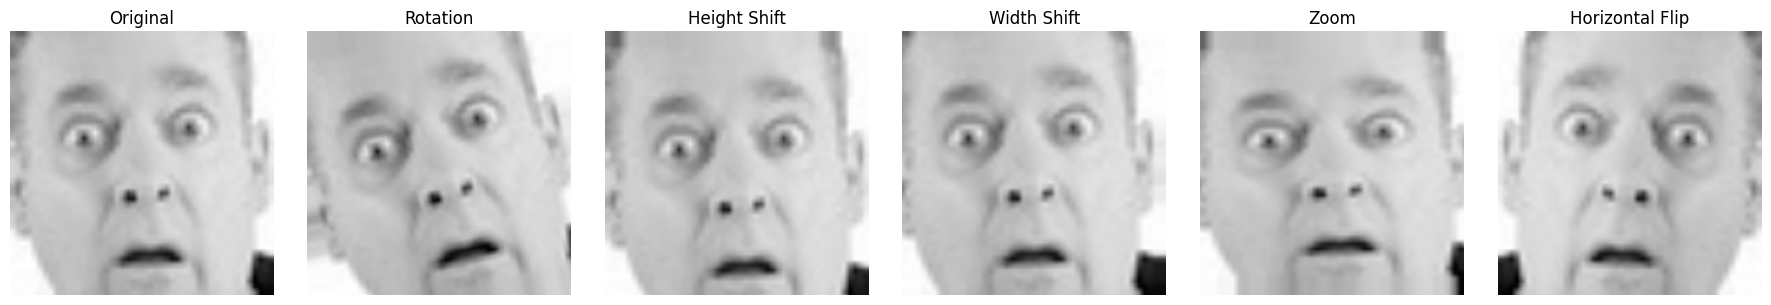

Saved: C:/Users/Alfariza Rasendria/Downloads/Skripsi/Skripsi/FIX SEMHAS/Program/Dataset/Prepocessing Output Sample/Augmentation\augmentation_results.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img = img_FER_Resized_RGB

# Save folder
save_folder = "C:/Users/Alfariza Rasendria/Downloads/Skripsi/Skripsi/FIX SEMHAS/Program/Dataset/Prepocessing Output Sample/Augmentation"
os.makedirs(save_folder, exist_ok=True)

# Augmentation configuration
augmentations = {
    "Rotation": ImageDataGenerator(rotation_range=20),
    "Width Shift": ImageDataGenerator(width_shift_range=0.1),
    "Height Shift": ImageDataGenerator(height_shift_range=0.1),
    "Zoom": ImageDataGenerator(zoom_range=[0.8, 1.2]),
    "Horizontal Flip": ImageDataGenerator(horizontal_flip=True)
}

# Image dimensions
height, width = img.shape[:2]

plt.figure(figsize=(18, 3))

# =========================================================
# Original
# =========================================================
plt.subplot(1, 6, 1)
plt.imshow(img[:, :, 0], cmap="gray")
plt.title("Original")
plt.axis("off")


# =========================================================
# Rotation
# =========================================================
aug = augmentations["Rotation"]

theta = np.random.uniform(
    -aug.rotation_range,
    aug.rotation_range
)

transform = aug.get_random_transform(img.shape)
transform["theta"] = theta

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(f"Rotation -> theta: {theta:.2f}°")

plt.subplot(1, 6, 2)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Rotation")
plt.axis("off")


# =========================================================
# Width Shift
# =========================================================
aug = augmentations["Width Shift"]

shift_range = aug.width_shift_range * width

tx = np.random.uniform(
    -shift_range,
    shift_range
)

transform = aug.get_random_transform(img.shape)
transform["tx"] = tx

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(f"Width Shift -> tx: {tx:.2f} px")

plt.subplot(1, 6, 3)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Width Shift")
plt.axis("off")


# =========================================================
# Height Shift
# =========================================================
aug = augmentations["Height Shift"]

shift_range = aug.height_shift_range * height

ty = np.random.uniform(
    -shift_range,
    shift_range
)

transform = aug.get_random_transform(img.shape)
transform["ty"] = ty

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(f"Height Shift -> ty: {ty:.2f} px")

plt.subplot(1, 6, 4)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Height Shift")
plt.axis("off")


# =========================================================
# Zoom
# =========================================================
aug = augmentations["Zoom"]

transform = aug.get_random_transform(img.shape)

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(
    f"Zoom -> zx: {transform['zx']:.2f}, "
    f"zy: {transform['zy']:.2f}"
)

plt.subplot(1, 6, 5)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Zoom")
plt.axis("off")


# =========================================================
# Horizontal Flip
# =========================================================
aug = augmentations["Horizontal Flip"]

transform = aug.get_random_transform(img.shape)

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(
    f"Horizontal Flip -> "
    f"{transform['flip_horizontal']}"
)

plt.subplot(1, 6, 6)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Horizontal Flip")
plt.axis("off")


# =========================================================
# Save
# =========================================================
plt.tight_layout()

save_path = os.path.join(
    save_folder,
    "FER2013_augmentation_results.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved: {save_path}")

Rotation -> theta: -12.32
Width Shift -> tx: 17.79
Height Shift -> ty: 21.13
Zoom -> zx: 0.87, zy: 1.0
Horizontal Flip -> 1


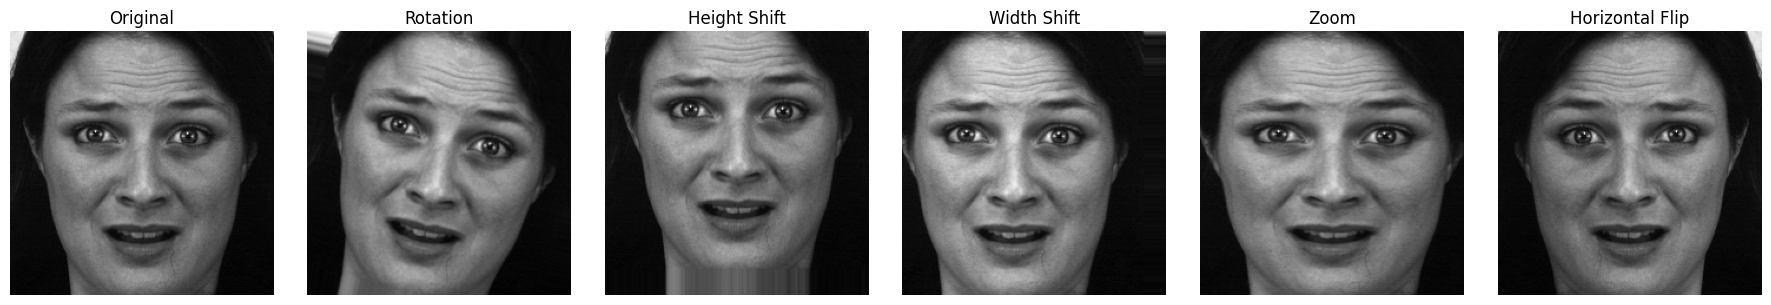

Saved: C:/Users/Alfariza Rasendria/Downloads/Skripsi/Skripsi/FIX SEMHAS/Program/Dataset/Prepocessing Output Sample/Augmentation\KDEF_augmentation_results.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img = img_KDEF_Resized_RGB

# Save folder
save_folder = "C:/Users/Alfariza Rasendria/Downloads/Skripsi/Skripsi/FIX SEMHAS/Program/Dataset/Prepocessing Output Sample/Augmentation"
os.makedirs(save_folder, exist_ok=True)

# Augmentation configuration
augmentations = {
    "Rotation": ImageDataGenerator(rotation_range=20),
    "Width Shift": ImageDataGenerator(width_shift_range=0.1),
    "Height Shift": ImageDataGenerator(height_shift_range=0.1),
    "Zoom": ImageDataGenerator(zoom_range=[0.8, 1.2]),
    "Horizontal Flip": ImageDataGenerator(horizontal_flip=True)
}

# Image dimensions
height, width = img.shape[:2]

plt.figure(figsize=(18, 3))

# =========================================================
# Original
# =========================================================
plt.subplot(1, 6, 1)
plt.imshow(img[:, :, 0], cmap="gray")
plt.title("Original")
plt.axis("off")


# =========================================================
# Rotation
# =========================================================
aug = augmentations["Rotation"]

theta = np.random.uniform(
    -aug.rotation_range,
    aug.rotation_range
)

transform = aug.get_random_transform(img.shape)
transform["theta"] = theta

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(f"Rotation -> theta: {theta:.2f}°")

plt.subplot(1, 6, 2)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Rotation")
plt.axis("off")


# =========================================================
# Width Shift
# =========================================================
aug = augmentations["Width Shift"]

shift_range = aug.width_shift_range * width

tx = np.random.uniform(
    -shift_range,
    shift_range
)

transform = aug.get_random_transform(img.shape)
transform["tx"] = tx

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(f"Width Shift -> tx: {tx:.2f} px")

plt.subplot(1, 6, 3)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Width Shift")
plt.axis("off")


# =========================================================
# Height Shift
# =========================================================
aug = augmentations["Height Shift"]

shift_range = aug.height_shift_range * height

ty = np.random.uniform(
    -shift_range,
    shift_range
)

transform = aug.get_random_transform(img.shape)
transform["ty"] = ty

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(f"Height Shift -> ty: {ty:.2f} px")

plt.subplot(1, 6, 4)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Height Shift")
plt.axis("off")


# =========================================================
# Zoom
# =========================================================
aug = augmentations["Zoom"]

transform = aug.get_random_transform(img.shape)

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(
    f"Zoom -> zx: {transform['zx']:.2f}, "
    f"zy: {transform['zy']:.2f}"
)

plt.subplot(1, 6, 5)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Zoom")
plt.axis("off")


# =========================================================
# Horizontal Flip
# =========================================================
aug = augmentations["Horizontal Flip"]

transform = aug.get_random_transform(img.shape)

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(
    f"Horizontal Flip -> "
    f"{transform['flip_horizontal']}"
)

plt.subplot(1, 6, 6)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Horizontal Flip")
plt.axis("off")


# =========================================================
# Save
# =========================================================
plt.tight_layout()

save_path = os.path.join(
    save_folder,
    "KDEF_augmentation_results.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved: {save_path}")

Rotation -> theta: -16.46°
Width Shift -> tx: -1.92 px
Height Shift -> ty: -20.83 px
Zoom -> zx: 0.88, zy: 0.82
Horizontal Flip -> 1


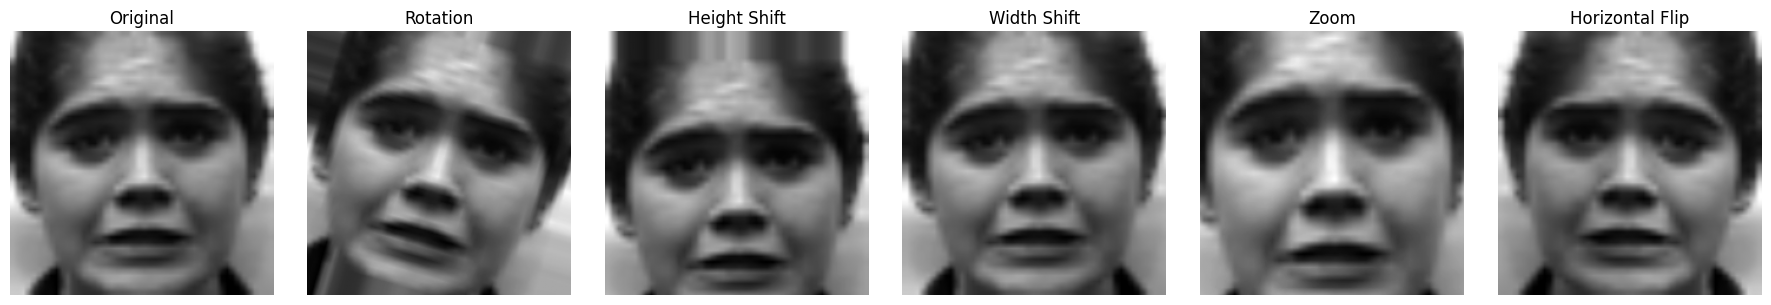

Saved: C:/Users/Alfariza Rasendria/Downloads/Skripsi/Skripsi/FIX SEMHAS/Program/Dataset/Prepocessing Output Sample/Augmentation\CK_augmentation_results.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img = img_CK_Resized_RGB

# Save folder
save_folder = "C:/Users/Alfariza Rasendria/Downloads/Skripsi/Skripsi/FIX SEMHAS/Program/Dataset/Prepocessing Output Sample/Augmentation"
os.makedirs(save_folder, exist_ok=True)

# Augmentation configuration
augmentations = {
    "Rotation": ImageDataGenerator(rotation_range=20),
    "Width Shift": ImageDataGenerator(width_shift_range=0.1),
    "Height Shift": ImageDataGenerator(height_shift_range=0.1),
    "Zoom": ImageDataGenerator(zoom_range=[0.8, 1.2]),
    "Horizontal Flip": ImageDataGenerator(horizontal_flip=True)
}

# Image dimensions
height, width = img.shape[:2]

plt.figure(figsize=(18, 3))

# =========================================================
# Original
# =========================================================
plt.subplot(1, 6, 1)
plt.imshow(img[:, :, 0], cmap="gray")
plt.title("Original")
plt.axis("off")


# =========================================================
# Rotation
# =========================================================
aug = augmentations["Rotation"]

theta = np.random.uniform(
    -aug.rotation_range,
    aug.rotation_range
)

transform = aug.get_random_transform(img.shape)
transform["theta"] = theta

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(f"Rotation -> theta: {theta:.2f}°")

plt.subplot(1, 6, 2)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Rotation")
plt.axis("off")


# =========================================================
# Width Shift
# =========================================================
aug = augmentations["Width Shift"]

shift_range = aug.width_shift_range * width

tx = np.random.uniform(
    -shift_range,
    shift_range
)

transform = aug.get_random_transform(img.shape)
transform["tx"] = tx

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(f"Width Shift -> tx: {tx:.2f} px")

plt.subplot(1, 6, 3)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Width Shift")
plt.axis("off")


# =========================================================
# Height Shift
# =========================================================
aug = augmentations["Height Shift"]

shift_range = aug.height_shift_range * height

ty = np.random.uniform(
    -shift_range,
    shift_range
)

transform = aug.get_random_transform(img.shape)
transform["ty"] = ty

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(f"Height Shift -> ty: {ty:.2f} px")

plt.subplot(1, 6, 4)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Height Shift")
plt.axis("off")


# =========================================================
# Zoom
# =========================================================
aug = augmentations["Zoom"]

transform = aug.get_random_transform(img.shape)

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(
    f"Zoom -> zx: {transform['zx']:.2f}, "
    f"zy: {transform['zy']:.2f}"
)

plt.subplot(1, 6, 5)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Zoom")
plt.axis("off")


# =========================================================
# Horizontal Flip
# =========================================================
aug = augmentations["Horizontal Flip"]

transform = aug.get_random_transform(img.shape)

aug_img = aug.apply_transform(
    img,
    transform
).astype(np.uint8)

print(
    f"Horizontal Flip -> "
    f"{transform['flip_horizontal']}"
)

plt.subplot(1, 6, 6)
plt.imshow(aug_img[:, :, 0], cmap="gray")
plt.title("Horizontal Flip")
plt.axis("off")


# =========================================================
# Save
# =========================================================
plt.tight_layout()

save_path = os.path.join(
    save_folder,
    "CK_augmentation_results.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved: {save_path}")

# Preprocessing Input ResNet

In [44]:
img_FER_preprocess_input = preprocess_input(img_FER_Resized_RGB.astype(np.float32))
img_KDEF_preprocess_input = preprocess_input(img_KDEF_Resized_RGB.astype(np.float32))
img_CK_preprocess_input = preprocess_input(img_CK_Resized_RGB.astype(np.float32))

In [45]:
print(img_FER_preprocess_input.shape)
print(img_KDEF_preprocess_input.shape)
print(img_CK_preprocess_input.shape)

(224, 224, 3)
(224, 224, 3)
(224, 224, 3)


In [46]:
print("FER preprocess_input :", np.mean(img_FER_Resized_RGB))
print("FER preprocess_input :", np.mean(img_FER_preprocess_input))

FER preprocess_input : 195.97554607780611
FER preprocess_input : 81.176216


In [47]:
print("KDEF preprocess_input:", np.mean(img_KDEF_Resized_RGB))
print("KDEF preprocess_input:", np.mean(img_KDEF_preprocess_input))

KDEF preprocess_input: 41.54711415816327
KDEF preprocess_input: -73.25222


In [48]:
print("CK preprocess_input :", np.mean(img_CK_Resized_RGB))
print("CK preprocess_input :", np.mean(img_CK_preprocess_input))

CK preprocess_input : 96.34526466836735
CK preprocess_input : -18.45407
